<a href="https://colab.research.google.com/github/afif-af/dl_python/blob/main/deepLearningWithPython.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 03

In [ ]:
import tensorflow as tf
x=tf.ones(shape=(2,1))

In [ ]:
print(x)

tf.Tensor(
[[1.]
 [1.]], shape=(2, 1), dtype=float32)


In [ ]:
x=tf.zeros(shape=(2,1))

In [ ]:
print(x)

tf.Tensor(
[[0.]
 [0.]], shape=(2, 1), dtype=float32)


In [ ]:
x=tf.random.normal(shape=(3,1),mean=0.,stddev=1.)

In [ ]:
print(x)

tf.Tensor(
[[0.9342705]
 [1.4016457]
 [2.5098665]], shape=(3, 1), dtype=float32)


In [ ]:
x=tf.random.uniform(shape=(3,1),minval=0.,maxval=1.)

In [ ]:
print(x)

tf.Tensor(
[[0.44068813]
 [0.09498715]
 [0.5579798 ]], shape=(3, 1), dtype=float32)


In [ ]:
x

<tf.Tensor: shape=(3, 1), dtype=float32, numpy=
array([[0.44068813],
       [0.09498715],
       [0.5579798 ]], dtype=float32)>

In [ ]:
import numpy as np
x=np.ones(shape=(2,2))
x[0,0]=0.

In [ ]:
x=tf.ones(shape=(2,2))
# x[0,0]=0.

In [ ]:
v=tf.Variable(initial_value=tf.random.normal(shape=(3,1)))

In [ ]:
print(v)

<tf.Variable 'Variable:0' shape=(3, 1) dtype=float32, numpy=
array([[-0.7102739 ],
       [ 0.24858817],
       [-0.21868786]], dtype=float32)>


In [ ]:
v.assign(tf.ones((3,1)))


<tf.Variable 'UnreadVariable' shape=(3, 1) dtype=float32, numpy=
array([[1.],
       [1.],
       [1.]], dtype=float32)>

In [ ]:
v[0,0].assign(3.)

<tf.Variable 'UnreadVariable' shape=(3, 1) dtype=float32, numpy=
array([[3.],
       [1.],
       [1.]], dtype=float32)>

In [ ]:
v.assign_add(tf.ones((3,1)))

<tf.Variable 'UnreadVariable' shape=(3, 1) dtype=float32, numpy=
array([[4.],
       [2.],
       [2.]], dtype=float32)>

In [ ]:
a=tf.ones((2,2))
b=tf.square(a)
c=tf.sqrt(a)
d=b+c
e=tf.matmul(a,b)
e*=d

In [ ]:
input_var=tf.Variable(initial_value=3.)
with tf.GradientTape() as tape:
  result=tf.square(input_var)
grandient=tape.gradient(result,input_var)


In [ ]:
input_const=tf.constant(3.)
with tf.GradientTape() as tape:
  tape.watch(input_const)
  result=tf.square (input_const)
gradient=tape.gradient(result, input_const)

In [ ]:
time=tf.Variable(0.)
with tf.GradientTape() as outer_tape:
  with tf.GradientTape() as inner_tape:
    position=4.9*time**2
  speed= inner_tape.gradient(position,time)
acceleration=outer_tape.gradient(speed,time)

In [ ]:
num_samples_per_class=1000
negative_samples=np.random.multivariate_normal(
    mean=[0,3],
    cov=[[1,0.5],[0.5,1]],
    size=num_samples_per_class
)
positive_samples=np.random.multivariate_normal(
    mean=[3,0],
    cov=[[1,0.5],[0.5,1]],
    size=num_samples_per_class
)


In [ ]:
inputs=np.vstack((negative_samples,positive_samples)).astype(np.float32)

In [ ]:
targets=np.vstack((np.zeros((num_samples_per_class,1),dtype="float32"),
                   np.ones((num_samples_per_class,1),dtype="float32")))

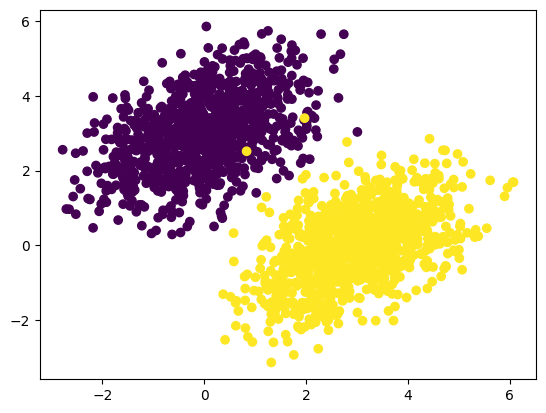

In [ ]:
import matplotlib.pyplot as plt
plt.scatter(inputs[:,0],inputs[:,1],c=targets[:,0])
plt.show()

In [ ]:
input_dim=2
output_dim=1
w=tf.Variable(initial_value=tf.random.uniform(shape=(input_dim,output_dim)))
b=tf.Variable(initial_value=tf.zeros(shape=(output_dim,)))

In [ ]:
def model(inputs):
  return tf.matmul(inputs,w)+b

In [ ]:
def square_loss(targets,predictions):
  per_sample_losses=tf.square(targets-predictions)
  return tf.reduce_mean(per_sample_losses)

In [ ]:
learning_rate=0.1
def training_step(inputs,targets):
  with tf.GradientTape() as tape:
    predictions=model(inputs)
    loss=square_loss(predictions,targets)
  grad_loss_w,grad_loss_b=tape.gradient(loss,[w,b])
  w.assign_sub(grad_loss_w* learning_rate)
  b.assign_sub(grad_loss_b* learning_rate)
  return loss

In [ ]:
for step in range(40):
  loss=training_step(inputs,targets)
  print(f"loss{step}: {loss:.4f}")

loss0: 0.8341
loss1: 0.1371
loss2: 0.0980
loss3: 0.0885
loss4: 0.0829
loss5: 0.0780
loss6: 0.0736
loss7: 0.0695
loss8: 0.0659
loss9: 0.0625
loss10: 0.0594
loss11: 0.0566
loss12: 0.0540
loss13: 0.0516
loss14: 0.0494
loss15: 0.0474
loss16: 0.0456
loss17: 0.0440
loss18: 0.0424
loss19: 0.0410
loss20: 0.0398
loss21: 0.0386
loss22: 0.0375
loss23: 0.0366
loss24: 0.0357
loss25: 0.0348
loss26: 0.0341
loss27: 0.0334
loss28: 0.0328
loss29: 0.0322
loss30: 0.0317
loss31: 0.0312
loss32: 0.0308
loss33: 0.0304
loss34: 0.0300
loss35: 0.0296
loss36: 0.0293
loss37: 0.0291
loss38: 0.0288
loss39: 0.0286


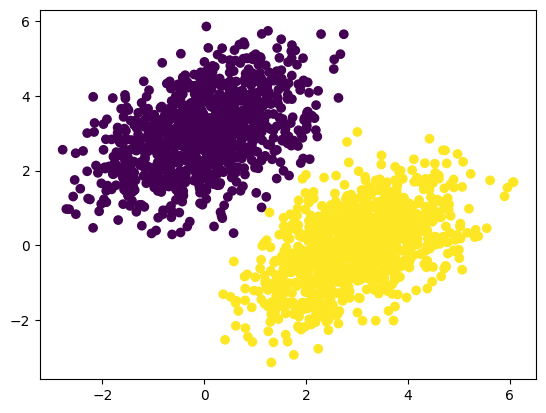

In [ ]:
predictions=model(inputs)
plt.scatter(inputs[:,0],inputs[:,1],c=predictions[:,0]>0.5)
plt.show()

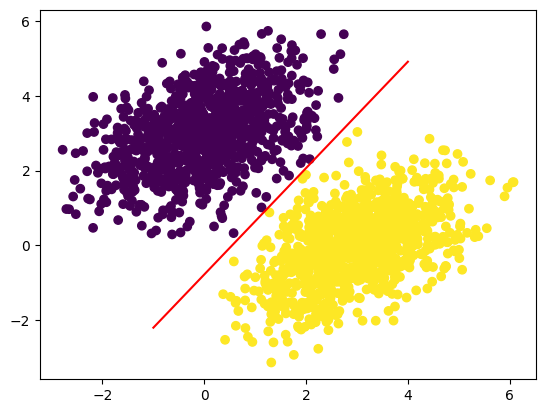

In [ ]:
x=np.linspace(-1,4,100)
y=-w[0]/w[1]*x+(0.5-b)/w[1]
plt.plot(x,y,"-r")
plt.scatter(inputs[:,0],inputs[:,1],c=predictions[:,0]>0.5)


In [ ]:
from tensorflow import keras

In [ ]:
class SimpleDense(keras.layers.Layer):
  def __init__(self,units,activation=None):
    super().__init__()
    self.units=units
    self.activation=activation

  def build(self,input_shape):
    input_dim=input_shape[-1]
    self.w=self.add_weight(shape=(input_dim,self.units),
                           initializer="random_normal")
    self.b=self.add_weight(shape=(self.units,),
                           initializer="zeros")
  def call(self,inputs):
    y=tf.matmul(inputs,self.w)+self.b
    if self.activation is not None:
      y=self.activation(y)
    return y

In [ ]:
my_dense = SimpleDense(units=32, activation=tf.nn.relu)
input_tensor = tf.ones(shape=(2, 784))
output_tensor = my_dense(input_tensor)
print(output_tensor.shape)

(2, 32)


In [ ]:
from tensorflow.keras import layers
layer=layers.Dense(32,activation="relu")

In [ ]:
from tensorflow.keras import models,layers

In [ ]:
model=models.Sequential([
    layers.Dense(32,activation='relu'),
    layers.Dense(32)
])

In [ ]:
# model = NaiveSequential([
# NaiveDense(input_size=784, output_size=32, activation="relu"),
# NaiveDense(input_size=32, output_size=64, activation="relu"),
# NaiveDense(input_size=64, output_size=32, activation="relu"),
# NaiveDense(input_size=32, output_size=10, activation="softmax")
# ])

In [ ]:
def __call__(self, inputs):
  if not self.built:
    self.build(inputs.shape)
    self.built = True
  return self.call(inputs)

In [ ]:
model=keras.Sequential([
    SimpleDense(32,activation="relu"),
    SimpleDense(64,activation="relu"),
    SimpleDense(32,activation="relu"),
    SimpleDense(10,activation="softmax"),
])

In [ ]:
model.compile(optimizer=keras.optimizers.RMSprop(),
  loss=keras.losses.MeanSquaredError(),
  metrics=[keras.metrics.BinaryAccuracy()])

In [ ]:
# model.compile(optimizer=keras.optimizers.RMSprop(learning_rate=1e-4),
# loss=my_custom_loss,
# metrics=[my_custom_metric_1, my_custom_metric_2])

In [ ]:
# history = model.fit(
# inputs,
# targets,
# epochs=5,
# batch_size=128
# )

In [ ]:
model=keras.Sequential([keras.layers.Dense(1)])
model.compile(optimizer=keras.optimizers.RMSprop(learning_rate=0.1),
              loss=keras.losses.MeanSquaredError(),
              metrics=[keras.metrics.BinaryAccuracy()])

In [ ]:
indices_permutation = np.random.permutation(len(inputs))
shuffled_inputs = inputs[indices_permutation]
shuffled_targets = targets[indices_permutation]

num_validation_samples = int(0.3 * len(inputs))
val_inputs = shuffled_inputs[:num_validation_samples]
val_targets = shuffled_targets[:num_validation_samples]

training_inputs = shuffled_inputs[num_validation_samples:]
training_targets = shuffled_targets[num_validation_samples:]

model.fit(
training_inputs,
training_targets,
epochs=5,
batch_size=16,
validation_data=(val_inputs, val_targets)
)

Epoch 1/5
88/88 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - binary_accuracy: 0.8057 - loss: 0.3922 - val_binary_accuracy: 0.9983 - val_loss: 0.0331
Epoch 2/5
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - binary_accuracy: 0.9655 - loss: 0.0663 - val_binary_accuracy: 1.0000 - val_loss: 0.0386
Epoch 3/5
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - binary_accuracy: 0.9675 - loss: 0.0750 - val_binary_accuracy: 0.9817 - val_loss: 0.0441
Epoch 4/5
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - binary_accuracy: 0.9611 - loss: 0.0651 - val_binary_accuracy: 0.9467 - val_loss: 0.1315
Epoch 5/5
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - binary_accuracy: 0.9658 - loss: 0.0724 - val_binary_accuracy: 0.8817 - val_loss: 0.1065


In [ ]:
loss_andf_metrics=model.evaluate(val_inputs,val_targets,batch_size=128)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - binary_accuracy: 0.8779 - loss: 0.1081


In [ ]:
predictions=model.predict(val_inputs,batch_size=128)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step


In [ ]:
print(predictions[:10])

[[0.38607088]
 [0.47883126]
 [0.31868055]
 [0.29862297]
 [0.42049393]
 [1.15751   ]
 [0.3463308 ]
 [0.6476399 ]
 [0.24893054]
 [0.62781525]]


# Chapter 04

In [ ]:
from tensorflow.keras.datasets import imdb
(train_data,train_label),(test_data,test_label)=imdb.load_data(num_words=10000)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
train_data[0]

[1,
 14,
 22,
 16,
 43,
 530,
 973,
 1622,
 1385,
 65,
 458,
 4468,
 66,
 3941,
 4,
 173,
 36,
 256,
 5,
 25,
 100,
 43,
 838,
 112,
 50,
 670,
 2,
 9,
 35,
 480,
 284,
 5,
 150,
 4,
 172,
 112,
 167,
 2,
 336,
 385,
 39,
 4,
 172,
 4536,
 1111,
 17,
 546,
 38,
 13,
 447,
 4,
 192,
 50,
 16,
 6,
 147,
 2025,
 19,
 14,
 22,
 4,
 1920,
 4613,
 469,
 4,
 22,
 71,
 87,
 12,
 16,
 43,
 530,
 38,
 76,
 15,
 13,
 1247,
 4,
 22,
 17,
 515,
 17,
 12,
 16,
 626,
 18,
 2,
 5,
 62,
 386,
 12,
 8,
 316,
 8,
 106,
 5,
 4,
 2223,
 5244,
 16,
 480,
 66,
 3785,
 33,
 4,
 130,
 12,
 16,
 38,
 619,
 5,
 25,
 124,
 51,
 36,
 135,
 48,
 25,
 1415,
 33,
 6,
 22,
 12,
 215,
 28,
 77,
 52,
 5,
 14,
 407,
 16,
 82,
 2,
 8,
 4,
 107,
 117,
 5952,
 15,
 256,
 4,
 2,
 7,
 3766,
 5,
 723,
 36,
 71,
 43,
 530,
 476,
 26,
 400,
 317,
 46,
 7,
 4,
 2,
 1029,
 13,
 104,
 88,
 4,
 381,
 15,
 297,
 98,
 32,
 2071,
 56,
 26,
 141,
 6,
 194,
 7486,
 18,
 4,
 226,
 22,
 21,
 134,
 476,
 26,
 480,
 5,
 144,
 30,
 5535,
 18,

In [ ]:
train_label[0]

np.int64(1)

In [ ]:
max([max(sequence) for sequence in train_data])

9999

In [ ]:
world_index=imdb.get_word_index()
reverse_word_index=dict(
    [(value,key) for (key, value) in world_index.items()]
)
deconded_review=" ".join(
    [reverse_word_index.get(i-3,"?") for i in train_data[0]]
)

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
import numpy as np
def vectorize_sequences(sequences,dimention=10000):
  results=np.zeros((len(sequences),dimention))
  for i ,sequence in enumerate(sequences):
    for j in sequence:
      results[i,j]=1.
  return results

x_train=vectorize_sequences(train_data)
y_train=vectorize_sequences(test_data)

In [ ]:
x_train[0]

array([0., 1., 1., ..., 0., 0., 0.])

In [ ]:
y_train=np.asarray(train_label).astype("float32")
y_test=np.asarray(test_label).astype("float32")

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

model=keras.Sequential([
    layers.Dense(16,activation="relu"),
    layers.Dense(16,activation="relu"),
    layers.Dense(1,activation="sigmoid")
])


In [ ]:
model.compile(optimizer="rmsprop",
              loss="binary_crossentropy",
              metrics=["accuracy"])

In [ ]:
x_val=x_train[:10000]
partial_x_train=x_train[10000:]
y_val=y_train[:10000]
partial_y_train=y_train[10000:]

In [ ]:
history=model.fit(partial_x_train,
                  partial_y_train,
                  epochs=20,
                  batch_size=512,
                  validation_data=(x_val,y_val))

Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.6979 - loss: 0.5922 - val_accuracy: 0.8536 - val_loss: 0.3961
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.8949 - loss: 0.3279 - val_accuracy: 0.8855 - val_loss: 0.3070
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9296 - loss: 0.2287 - val_accuracy: 0.8833 - val_loss: 0.2908
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9436 - loss: 0.1832 - val_accuracy: 0.8859 - val_loss: 0.2801
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9561 - loss: 0.1476 - val_accuracy: 0.8885 - val_loss: 0.2811
Epoch 6/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9602 - loss: 0.1329 - val_accuracy: 0.8885 - val_loss: 0.2872
Epoch 7/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9715 - loss: 0.1068 - val_accuracy: 0.8716 - val_loss: 0.3310
Epoch 8/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9688 - loss: 0.0984 - val_accuracy: 0.8815 - v

In [ ]:
histor_dict=history.history
histor_dict.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

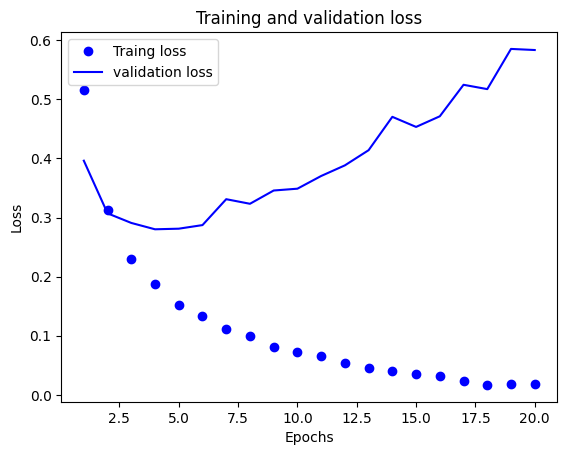

In [ ]:
import matplotlib.pyplot as plt
history_dict=history.history
loss_value=history_dict["loss"]
val_loss_values=history_dict["val_loss"]
epochs=range(1,len(loss_value)+1)
plt.plot(epochs,loss_value,"bo",label="Traing loss")
plt.plot(epochs,val_loss_values,"b",label="validation loss")
plt.title("Training and validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

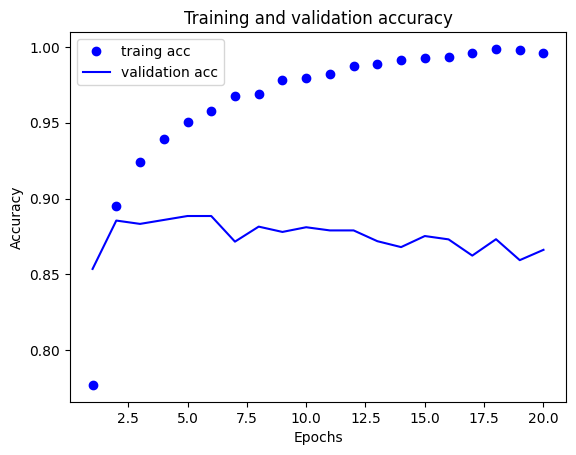

In [ ]:
plt.clf()
acc=history_dict["accuracy"]
val_acc=history_dict["val_accuracy"]
plt.plot(epochs,acc,"bo",label="traing acc")
plt.plot(epochs,val_acc,"b",label="validation acc")
plt.title("Training and validation accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [ ]:
# model = keras.Sequential([
# layers.Dense(16, activation="relu"),
# layers.Dense(16, activation="relu"),
#                            layers.Dense(1, activation="sigmoid")
# ])
# model.compile(optimizer="rmsprop",
# loss="binary_crossentropy",
# metrics=["accuracy"])
# model.fit(x_train, y_train, epochs=4, batch_size=512)
# results = model.evaluate(train_data, y_test)

In [ ]:
# results

In [ ]:
# model.predict(x_test)

In [ ]:
from tensorflow.keras.datasets import reuters
(train_data, train_labels), (test_data, test_labels) = reuters.load_data(
num_words=10000)

2110848/2110848 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
len(train_data)

8982

In [ ]:
len(test_data)

2246

In [ ]:
train_data[10]

[1,
 245,
 273,
 207,
 156,
 53,
 74,
 160,
 26,
 14,
 46,
 296,
 26,
 39,
 74,
 2979,
 3554,
 14,
 46,
 4689,
 4329,
 86,
 61,
 3499,
 4795,
 14,
 61,
 451,
 4329,
 17,
 12]

In [ ]:
word_index = reuters.get_word_index()
reverse_word_index = dict(
[(value, key) for (key, value) in word_index.items()])
decoded_newswire = " ".join(
[reverse_word_index.get(i - 3, "?") for i in train_data[0]])

550378/550378 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
train_label[10]

np.int64(1)

In [ ]:
x_train = vectorize_sequences(train_data)
x_test = vectorize_sequences(test_data)


In [ ]:
def to_one_hot(labels, dimension=46):
    results = np.zeros((len(labels), dimension))
    for i, label in enumerate(labels):
        results[i, label] = 1.
    return results

y_train = to_one_hot(train_labels)
y_test = to_one_hot(test_labels)


In [ ]:
from tensorflow.keras.utils import to_categorical
y_train = to_categorical(train_labels)
y_test = to_categorical(test_labels)

In [ ]:
model = keras.Sequential([
layers.Dense(64, activation="relu"),
layers.Dense(64, activation="relu"),
layers.Dense(46, activation="softmax")
])

In [ ]:
model.compile(optimizer="rmsprop",
loss="categorical_crossentropy",
metrics=["accuracy"])

In [ ]:
x_val = x_train[:1000]
partial_x_train = x_train[1000:]
y_val = y_train[:1000]
partial_y_train = y_train[1000:]

In [ ]:
history=model.fit(partial_x_train,
                  partial_y_train,
                  epochs=20,
                  batch_size=512,
                  validation_data=(x_val,y_val))

Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.3851 - loss: 3.1719 - val_accuracy: 0.6080 - val_loss: 1.7925
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.6688 - loss: 1.5633 - val_accuracy: 0.7050 - val_loss: 1.3438
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.7423 - loss: 1.1715 - val_accuracy: 0.7490 - val_loss: 1.1616
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.7923 - loss: 0.9547 - val_accuracy: 0.7690 - val_loss: 1.0685
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.8291 - loss: 0.7843 - val_accuracy: 0.7830 - val_loss: 0.9931
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.8535 - loss: 0.6745 - val_accuracy: 0.7950 - val_loss: 0.9417
Epoch 7/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.8833 - loss: 0.5467 - val_accuracy: 0.8110 - val_loss: 0.9002
Epoch 8/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.9012 - loss: 0.4718 - val_accuracy: 0.8110 - v

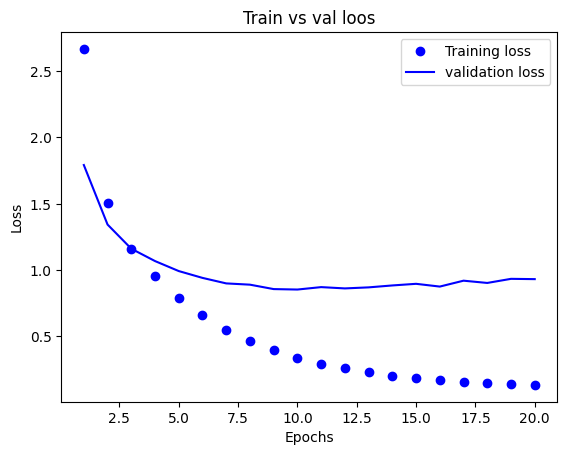

In [ ]:
loss=history.history["loss"]
val_loss=history.history["val_loss"]
epochs=range(1,len(loss)+1)
plt.plot(epochs,loss,"bo",label="Training loss")
plt.plot(epochs,val_loss,"b",label="validation loss")
plt.title("Train vs val loos")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

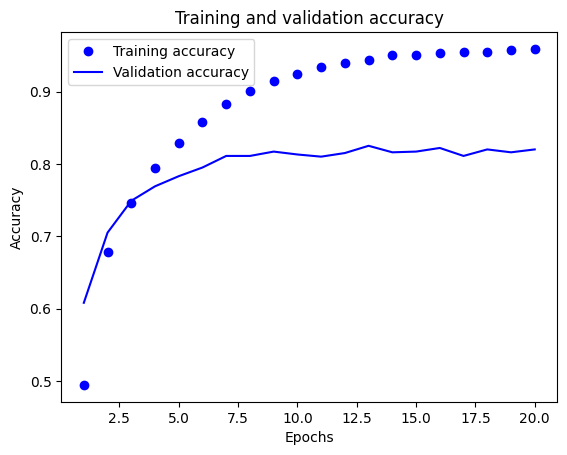

In [ ]:
plt.clf()
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
plt.plot(epochs, acc, "bo", label="Training accuracy")
plt.plot(epochs, val_acc, "b", label="Validation accuracy")
plt.title("Training and validation accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [ ]:
results=model.evaluate(x_test,y_test)

71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8048 - loss: 1.0200


In [ ]:
model = keras.Sequential([
layers.Dense(64, activation="relu"),
layers.Dense(64, activation="relu"),
layers.Dense(46, activation="softmax")
])
model.compile(optimizer="rmsprop",
loss="categorical_crossentropy",
metrics=["accuracy"])
model.fit(x_train,
y_train,
epochs=9,
batch_size=512)
results = model.evaluate(x_test, y_test)

Epoch 1/9
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.3569 - loss: 3.1962
Epoch 2/9
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.6723 - loss: 1.5888
Epoch 3/9
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.7428 - loss: 1.1895
Epoch 4/9
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.7968 - loss: 0.9440
Epoch 5/9
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.8301 - loss: 0.7889
Epoch 6/9
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.8625 - loss: 0.6507
Epoch 7/9
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.8946 - loss: 0.5183
Epoch 8/9
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9067 - loss: 0.4370
Epoch 9/9
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9266 - loss: 0.3598
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7922 - loss: 0.9129


In [ ]:
results

[0.9273819923400879, 0.7818343639373779]

In [ ]:
import copy
test_labels_copy=copy.copy(test_labels)
np.random.shuffle(test_labels_copy)
hits_array=np.array(test_labels)==np.array(test_labels_copy)
hits_array.mean()

np.float64(0.18076580587711488)

In [ ]:
predictions=model.predict(x_test)

71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [ ]:
predictions[0].shape

(46,)

In [ ]:
np.sum(predictions[0])

np.float32(0.9999999)

In [ ]:
np.argmax(predictions[0])

np.int64(3)

In [ ]:
y_train=np.array(train_labels)
y_test=np.array(test_labels)

In [ ]:
model.compile(optimizer="rmsprop",
              loss="sparce_categorical_crossentrophy",
              metrics=["accuracy"])

In [ ]:
model=keras.Sequential([
    layers.Dense(64,activation="relu"),
    layers.Dense(4,activation="relu"),
    layers.Dense(46,activation="softmax")
])

In [ ]:
model.compile(optimizer="rmsprop",
              loss="categorical_crossentropy",
              metrics=["accuracy"])

In [ ]:
# model.fit(partial_x_train,
# partial_y_train,
# epochs=20,
# batch_size=128,
# validation_data=(x_val, y_val))

In [ ]:
from tensorflow.keras.datasets import boston_housing

In [ ]:
(train_data,train_targets),(test_data,test_targets)=boston_housing.load_data()

57026/57026 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
train_data.shape

(404, 13)

In [ ]:
test_data.shape

(102, 13)

In [ ]:
train_targets

array([15.2, 42.3, 50. , 21.1, 17.7, 18.5, 11.3, 15.6, 15.6, 14.4, 12.1,
       17.9, 23.1, 19.9, 15.7,  8.8, 50. , 22.5, 24.1, 27.5, 10.9, 30.8,
       32.9, 24. , 18.5, 13.3, 22.9, 34.7, 16.6, 17.5, 22.3, 16.1, 14.9,
       23.1, 34.9, 25. , 13.9, 13.1, 20.4, 20. , 15.2, 24.7, 22.2, 16.7,
       12.7, 15.6, 18.4, 21. , 30.1, 15.1, 18.7,  9.6, 31.5, 24.8, 19.1,
       22. , 14.5, 11. , 32. , 29.4, 20.3, 24.4, 14.6, 19.5, 14.1, 14.3,
       15.6, 10.5,  6.3, 19.3, 19.3, 13.4, 36.4, 17.8, 13.5, 16.5,  8.3,
       14.3, 16. , 13.4, 28.6, 43.5, 20.2, 22. , 23. , 20.7, 12.5, 48.5,
       14.6, 13.4, 23.7, 50. , 21.7, 39.8, 38.7, 22.2, 34.9, 22.5, 31.1,
       28.7, 46. , 41.7, 21. , 26.6, 15. , 24.4, 13.3, 21.2, 11.7, 21.7,
       19.4, 50. , 22.8, 19.7, 24.7, 36.2, 14.2, 18.9, 18.3, 20.6, 24.6,
       18.2,  8.7, 44. , 10.4, 13.2, 21.2, 37. , 30.7, 22.9, 20. , 19.3,
       31.7, 32. , 23.1, 18.8, 10.9, 50. , 19.6,  5. , 14.4, 19.8, 13.8,
       19.6, 23.9, 24.5, 25. , 19.9, 17.2, 24.6, 13

In [ ]:
mean=train_data.mean(axis=0)
train_data-=mean
std=train_data.std(axis=0)
train_data/=std
test_data-=mean
test_data/=std

In [ ]:
def build_model():
  model=keras.Sequential([
      layers.Dense(64,activation="relu"),
      layers.Dense(64,activation="relu"),
      layers.Dense(1)
  ])
  model.compile(optimizer="rmsprop",loss="mse",metrics=["mae"])
  return model

In [ ]:
k=4
num_val_samples=len(train_data)//k
num_epochs=100
all_scores=[]
for i in range(k):
  print(f"processing fold #{i}")
  val_data=train_data[i*num_val_samples:(i+1)*num_val_samples]
  val_targets=train_targets[i*num_val_samples:(i+1)*num_val_samples]
  partial_train_data=np.concatenate(
      [train_data[:i*num_val_samples],
       train_data[(i+1)*num_val_samples:]],
      axis=0
  )
  partial_train_targets=np.concatenate(
      [train_targets[:i*num_val_samples],
       train_targets[(i+1)*num_val_samples:]],
      axis=0
  )
  model=build_model()
  model.fit(partial_train_data,
            partial_train_targets,
            epochs=num_epochs,batch_size=1,verbose=0)
  val_mse,val_mae=model.evaluate(val_data,val_targets,verbose=0)
  all_scores.append(val_mae)

processing fold #0
processing fold #1
processing fold #2


KeyboardInterrupt: 

In [ ]:
all_scores

In [ ]:
np.mean(all_scores)

In [ ]:
num_epochs = 500
all_mae_histories = []
for i in range(k):
  print(f"Processing fold #{i}")
  val_data = train_data[i * num_val_samples: (i + 1) * num_val_samples]
  val_targets = train_targets[i * num_val_samples: (i + 1) * num_val_samples]
  partial_train_data = np.concatenate(
  [train_data[:i * num_val_samples],
  train_data[(i + 1) * num_val_samples:]],
  axis=0)
  partial_train_targets = np.concatenate(
  [train_targets[:i * num_val_samples],
  train_targets[(i + 1) * num_val_samples:]],
  axis=0)
  model = build_model()
  history = model.fit(partial_train_data, partial_train_targets,
  validation_data=(val_data, val_targets),
  epochs=num_epochs, batch_size=16, verbose=0)
  mae_history = history.history["val_mae"]
  all_mae_histories.append(mae_history)

In [ ]:
average_mae_history=[
    np.mean([x[i]for x in all_mae_histories]) for i in range(num_epochs)
]

In [ ]:
plt.plot(range(1,len(average_mae_history)+1),average_mae_history)
plt.xlabel("Epochs")
plt.ylabel("validation MAE")
plt.show()

In [ ]:
truncated_mae_history=average_mae_history[10:]
plt.plot(range(1,len(truncated_mae_history)+1),truncated_mae_history)
plt.xlabel("Epochs")
plt.ylabel("Validation MAE")
plt.show()

In [ ]:
model=build_model()
model.fit(train_data,train_targets,epochs=80,batch_size=16,verbose=0)
test_mse_score,test_mae_score=model.evaluate(test_data,test_targets)

In [ ]:
test_mae_score

In [ ]:
predictions=model.predict(test_data)

In [ ]:
predictions[0]

# Chapter 05

In [ ]:
from tensorflow.keras.datasets import mnist

In [ ]:
import numpy as np


In [ ]:
(train_images,train_labels),_=mnist.load_data()

In [ ]:
train_images=train_images.reshape((60000,28*28))
train_images=train_images.astype("float32")/255

In [ ]:
train_images_with_noise_channels=np.concatenate(
    [train_images,np.random.random((len(train_images),784))],axis=1
)
train_images_with_zeros_channels=np.concatenate(
    [train_images,np.zeros((len(train_images),784))],axis=1
)

In [ ]:
from tensorflow import  keras
from tensorflow.keras import layers
def get_model():
  model=keras.Sequential([
      layers.Dense(512,activation="relu"),
      layers.Dense(10,activation="softmax")
  ])
  model.compile(optimizer="rmsprop",
               loss="sparse_categorical_crossentropy",
               metrics=["accuracy"])
  return model

model=get_model()
history_noise=model.fit(train_images_with_noise_channels,train_labels,
                        epochs=10,
                        batch_size=128,
                        validation_split=0.2)
model=get_model()
history_zeros=model.fit(
    train_images_with_zeros_channels,
    train_labels,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)

In [ ]:
import matplotlib.pyplot as plt
val_acc_noise=history_noise.history["val_accuracy"]
val_acc_zeros=history_zeros.history["val_accuracy"]
epochs=range(1,11)
plt.plot(epochs,val_acc_noise,"b-",label="Noise")
plt.plot(epochs,val_acc_zeros,"b--",label="Zeros")
plt.xlabel("Epochs")
plt.ylabel("Validation accuracy")
plt.legend()
plt.show()

In [ ]:
(train_images, train_labels), _ = mnist.load_data()
train_images = train_images.reshape((60000, 28 * 28))
train_images = train_images.astype("float32") / 255

In [ ]:
random_train_labels=train_labels[:]
np.random.shuffle(random_train_labels)
model=keras.Sequential([
    layers.Dense(512,activation="relu"),
    layers.Dense(10,activation="softmax")
])
model.compile(optimizer="rmsprop",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.fit(train_images,train_labels,epochs=10,batch_size=128,validation_split=0.2)


In [ ]:
# k = 3
# num_validation_samples = len(data) // k
# np.random.shuffle(data)
# validation_scores = []
# for fold in range(k):
#   validation_data = data[num_validation_samples * fold:
#   num_validation_samples * (fold + 1)]
#   training_data = np.concatenate(
#   data[:num_validation_samples * fold],
#   data[num_validation_samples * (fold + 1):])
#   model = get_model()
#   model.fit(training_data, ...)
#   validation_score = model.evaluate(validation_data, ...)
#   validation_scores.append(validation_score)
# validation_score = np.average(validation_scores)
# model = get_model()
# model.fit(data, ...)
# test_score = model.evaluate(test_data, ...)


In [ ]:
model = keras.Sequential([layers.Dense(10, activation="softmax")])
model.compile(optimizer="rmsprop",
loss="sparse_categorical_crossentropy",
metrics=["accuracy"])
history_small_model = model.fit(
train_images, train_labels,
epochs=20,
batch_size=128,
validation_split=0.2)



import matplotlib.pyplot as plt
val_loss = history_small_model.history["val_loss"]
epochs = range(1, 21)
plt.plot(epochs, val_loss, "b--",
label="Validation loss")
plt.title("Effect of insufficient model capacity on validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

In [ ]:
from tensorflow.keras.datasets import imdb
(train_data,train_labels),_=imdb.load_data(num_words=10000)
def vectorize_sequences(sequences,dimension=10000):
  results=np.zeros((len(sequences),dimension))
  for i,sequences in enumerate(sequences):
    results[i,sequences]=1.
  return results
train_data=vectorize_sequences(train_data)


In [ ]:
model=keras.Sequential([
    layers.Dense(16,activation="relu"),
    layers.Dense(16,activation="relu"),
    layers.Dense(1,activation="sigmoid")
])
model.compile(optimizer="rmsprop",
              loss="binary_crossentropy",
              metrics=["accuracy"])
history_original=model.fit(train_data,train_labels,epochs=20,
                           batch_size=512,validation_split=0.4)

In [ ]:
model=keras.Sequential([
    layers.Dense(4,activation="relu"),
    layers.Dense(4,activation="relu"),
    layers.Dense(1,activation="sigmoid")
])
model.compile(optimizer="rmsprop",
              loss="binary_crossentropy",
              metrics=["accuracy"])
history_original=model.fit(train_data,train_labels,epochs=20,
                           batch_size=512,validation_split=0.4)

In [ ]:
model=keras.Sequential([
    layers.Dense(512,activation="relu"),
    layers.Dense(512,activation="relu"),
    layers.Dense(1,activation="sigmoid")
])
model.compile(optimizer="rmsprop",
              loss="binary_crossentropy",
              metrics=["accuracy"])
history_original=model.fit(train_data,train_labels,epochs=20,
                           batch_size=512,validation_split=0.4)

In [ ]:
model.summary()

In [ ]:
from tensorflow.keras import regularizers
model=keras.Sequential([
    layers.Dense(16,
                 kernel_regularizer=regularizers.l2(0.002),
                 activation="relu"),
    layers.Dense(16,
                 kernel_regularizer=regularizers.l2(0.002),
                 activation="relu"),
    layers.Dense(1,
                 activation="sigmoid")
])
model.compile(optimizer="rmsprop",
              loss="binary_crossentropy",
              metrics=["accuracy"])
history_original=model.fit(train_data,train_labels,epochs=20,
                           batch_size=512,validation_split=0.4)

In [ ]:
model=keras.Sequential([
    layers.Dense(16,activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(16,activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1,activation="sigmoid"),
])

model.compile(optimizer="rmsprop",
              loss="binary_crossentropy",
              metrics=["accuracy"])
history_original=model.fit(train_data,train_labels,epochs=20,
                           batch_size=512,validation_split=0.4)

# chapter 07

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

model=keras.Sequential([
    layers.Dense(64,activation="relu"),
    layers.Dense(10,activation="softmax")
])

In [ ]:
model=keras.Sequential()

In [ ]:
model.add(layers.Dense(64,activation="relu"))
model.add(layers.Dense(10,activation="softmax"))

In [ ]:
model.weights

[]

In [ ]:
model.build(input_shape=(None,3))

In [ ]:
model.weights

[<Variable path=sequential_1/dense_2/kernel, shape=(3, 64), dtype=float32, value=[[-0.26115078 -0.01584956 -0.04932754 -0.05829328 -0.13943043  0.23191655
   -0.1777557   0.08109048  0.03833154  0.2428037  -0.2926775   0.2842577
   -0.1283902   0.12259522 -0.09516726 -0.00485998 -0.11681429 -0.2490265
   -0.04431081 -0.04486141  0.27302933 -0.11146981  0.02863616  0.279548
    0.2972114  -0.2074697  -0.2145781   0.21512353  0.13920525  0.12911296
   -0.23133284 -0.28838402 -0.01901987  0.18255424  0.21622288  0.27121472
    0.05027559  0.21570551  0.17940217  0.05195862 -0.12085477  0.15065616
   -0.14951931  0.17448255 -0.22704507  0.29217792  0.2884375   0.13268623
   -0.02100113 -0.11726956 -0.09103747 -0.24949789 -0.1636924   0.030644
   -0.13394652  0.23947763 -0.26916268  0.19928685  0.13433158 -0.2752322
    0.11972111  0.15565568 -0.03101009 -0.26966873]
  [ 0.12037703  0.20489377 -0.05341604  0.03443021  0.18350002 -0.2195588
   -0.29816383  0.06180236 -0.08305347 -0.22332922 

In [ ]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 64)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 906 (3.54 KB)

 Trainable params: 906 (3.54 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model=keras.Sequential(name="My_example_model")
model.add(layers.Dense(64,activation="relu",name="Fist Layer"))
model.add(layers.Dense(10,activation="softmax",name="Second Layer"))
model.build((None,3))
model.summary()

Model: "My_example_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Fist Layer (Dense)              │ (None, 64)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Second Layer (Dense)            │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 906 (3.54 KB)

 Trainable params: 906 (3.54 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model=keras.Sequential()
model.add(keras.Input(shape=(3,)))
model.add(layers.Dense(64,activation="relu"))


In [ ]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 64)             │           256 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 256 (1.00 KB)

 Trainable params: 256 (1.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.add(layers.Dense(10,activation="softmax"))

In [ ]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 64)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 906 (3.54 KB)

 Trainable params: 906 (3.54 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers


In [ ]:
inputs=keras.Input(shape=(3,),name="my_input")
features=layers.Dense(64,activation="relu")(inputs)
output=layers.Dense(10,activation="softmax")(features)
model=keras.Model(inputs=inputs,outputs=output)

In [ ]:
model.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ my_input (InputLayer)           │ (None, 3)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 906 (3.54 KB)

 Trainable params: 906 (3.54 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
inputs.shape

(None, 3)

In [ ]:
inputs.dtype

'float32'

In [ ]:
features.shape

(None, 64)

In [ ]:
vocabulary_size=10000
num_tags=100
num_departments=4

title=keras.Input(shape=(vocabulary_size,),name="title")
text_body=keras.Input(shape=(vocabulary_size,),name="text_body")
tags=keras.Input(shape=(num_tags,),name="tags")

features=layers.concatenate([title,text_body,tags])
features=layers.Dense(64,activation="relu")(features)

priority=layers.Dense(1,activation="sigmoid",name="priority")(features)
department=layers.Dense(num_departments,activation="softmax",name="department")(features)

model=keras.Model(inputs=[title,text_body,tags],outputs=[priority,department])



In [ ]:
import numpy as np
num_samples=1280

title_data=np.random.randint(0,2,size=(num_samples,vocabulary_size))
text_body_data=np.random.randint(0,2,size=(num_samples,vocabulary_size))
tags_data=np.random.randint(0,2,size=(num_samples,num_tags))

priority_data=np.random.random(size=(num_samples,1))
department_data=np.random.randint(0,2,size=(num_samples,num_departments))



model.compile(
    optimizer="rmsprop",
    loss=["mean_squared_error","categorical_crossentropy"],
    metrics=[["mean_absolute_error"],["accuracy"]]

)


model.fit([title_data,text_body_data,tags_data],
          [priority_data,department_data],
          epochs=1)

model.evaluate([title_data,text_body_data,tags_data],
               [priority_data,department_data])

priority_data,department_preds=model.predict([title_data,text_body_data,tags_data])

40/40 ━━━━━━━━━━━━━━━━━━━━ 8s 40ms/step - department_accuracy: 0.3311 - department_loss: 47.4393 - loss: 47.7460 - priority_loss: 0.3067 - priority_mean_absolute_error: 0.4687
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - department_accuracy: 0.5430 - department_loss: 40.4929 - loss: 40.8301 - priority_loss: 0.3372 - priority_mean_absolute_error: 0.5025
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step


In [ ]:
model.compile(optimizer="rmsprop",
loss={"priority": "mean_squared_error", "department":
"categorical_crossentropy"},
metrics={"priority": ["mean_absolute_error"], "department":
["accuracy"]})
model.fit({"title": title_data, "text_body": text_body_data,
"tags": tags_data},
{"priority": priority_data, "department": department_data},
epochs=1)
model.evaluate({"title": title_data, "text_body": text_body_data,
"tags": tags_data},
{"priority": priority_data, "department": department_data})
priority_preds, department_preds = model.predict(
{"title": title_data, "text_body": text_body_data, "tags": tags_data})

40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 52ms/step - department_accuracy: 0.3020 - department_loss: 44.8932 - loss: 44.8932 - priority_loss: 0.0000e+00 - priority_mean_absolute_error: 0.0000e+00
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - department_accuracy: 0.1507 - department_loss: 40.5793 - loss: 40.5793 - priority_loss: 0.0000e+00 - priority_mean_absolute_error: 0.0000e+00
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step


In [ ]:
model.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ title (InputLayer)  │ (None, 10000)     │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_body           │ (None, 10000)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tags (InputLayer)   │ (None, 100)       │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 20100)     │          0 │ title[0][0],      │
│ (Concatenate)       │                   │            │ text_body[0][0],  │
│                     │                   │            │ tags[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 64)        │  1,286,464 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ priority (Dense)    │ (None, 1)         │         65 │ dense_8[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ department (Dense)  │ (None, 4)         │        260 │ dense_8[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,573,580 (9.82 MB)

 Trainable params: 1,286,789 (4.91 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,286,791 (4.91 MB)

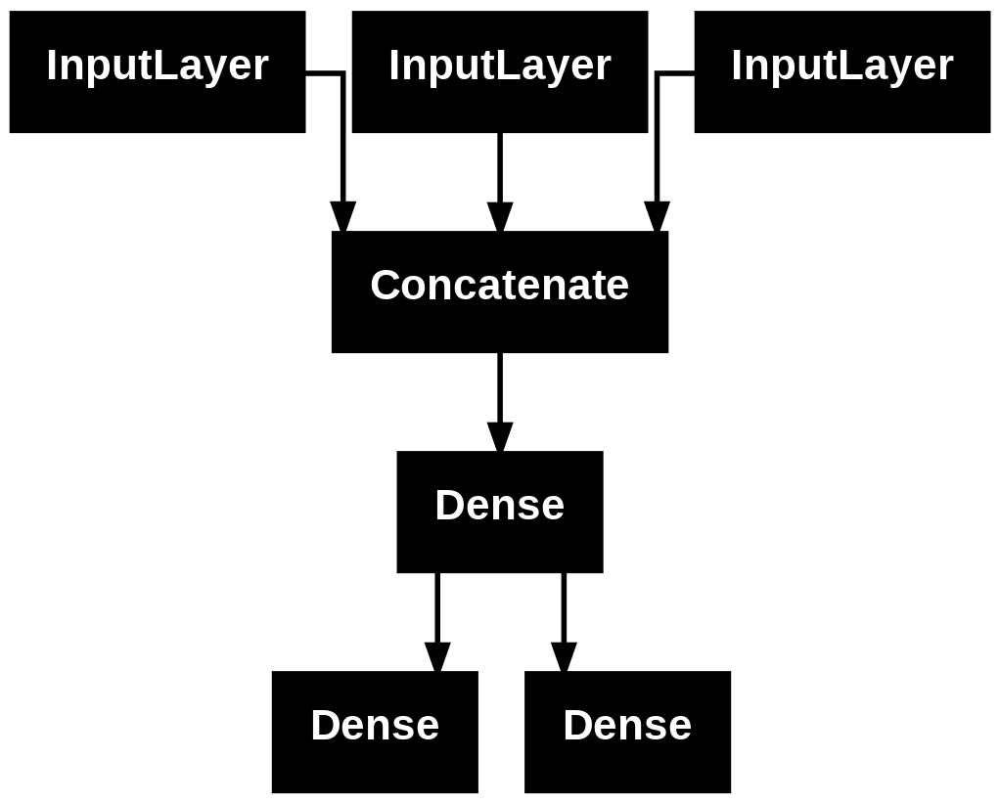

In [ ]:
keras.utils.plot_model(model, "ticket_classifier.png")

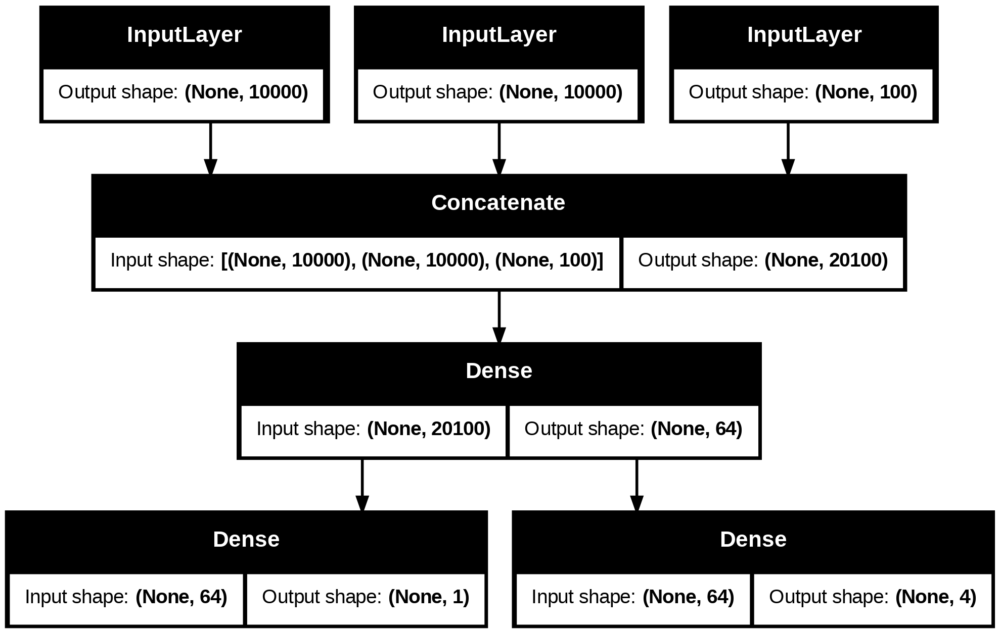

In [ ]:
keras.utils.plot_model(model, "ticket_classifier_with_shape_info.png",show_shapes=True)

In [ ]:
model.layers

[<InputLayer name=title, built=True>,
 <InputLayer name=text_body, built=True>,
 <InputLayer name=tags, built=True>,
 <Concatenate name=concatenate, built=True>,
 <Dense name=dense_8, built=True>,
 <Dense name=priority, built=True>,
 <Dense name=department, built=True>]

In [ ]:
model.layers[3].input

[<KerasTensor shape=(None, 10000), dtype=float32, sparse=False, name=title>,
 <KerasTensor shape=(None, 10000), dtype=float32, sparse=False, name=text_body>,
 <KerasTensor shape=(None, 100), dtype=float32, sparse=False, name=tags>]

In [ ]:
model.layers[3].output

<KerasTensor shape=(None, 20100), dtype=float32, sparse=False, name=keras_tensor_12>

In [ ]:
features=model.layers[4].output
difficulty=layers.Dense(3,activation="softmax",name="difficulty")(features)

new_model=keras.Model(
    inputs=[title,text_body,tags],
    outputs=[priority,department,difficulty]
)

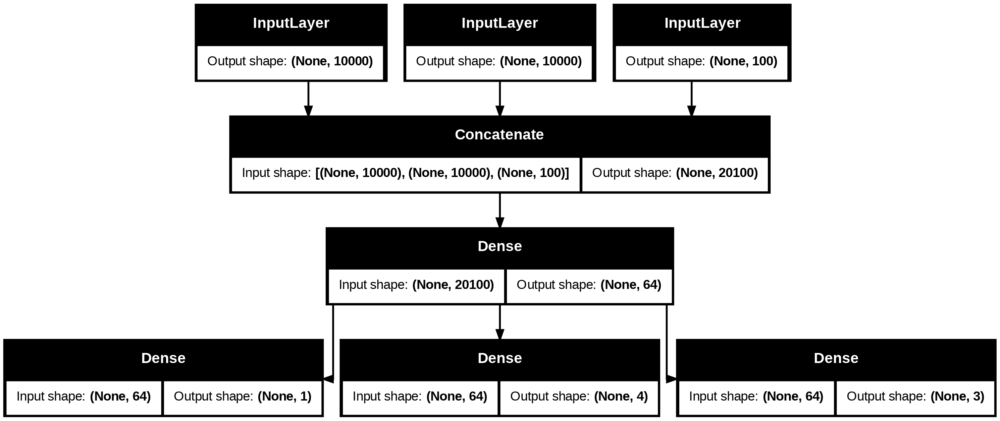

In [ ]:
keras.utils.plot_model(new_model,"updated_ticket_classifier.png",show_shapes=True)

In [ ]:
class CustomerTicketModel(keras.Model):
  def __init__(self,num_departments):
    super().__init__()
    self.concat_layer=layers.Concatenate()
    self.mixing_layer=layers.Dense(64,activation="relu")
    self.priority_scorer=layers.Dense(1,activation="sigmoid")
    self.department_classifier=layers.Dense(num_departments,activation="softmax")


  def call(self,inputs):
    title=inputs["title"]
    text_body=inputs["text_body"]
    tags=inputs["tags"]

    features=self.concat_layer([title,text_body,tags])
    features=self.mixing_layer(features)

    priority=self.priority_scorer(features)
    department=self.department_classifier(features)

    return priority,department

In [ ]:
model=CustomerTicketModel(num_departments=4)

In [ ]:
priority,department=model({"title":title_data,"text_body":text_body_data,"tags":tags_data})

In [ ]:
model.compile(optimizer="rmsprop",
loss=["mean_squared_error", "categorical_crossentropy"],
metrics=[["mean_absolute_error"], ["accuracy"]])
model.fit({"title": title_data,
"text_body": text_body_data,
"tags": tags_data},
[priority_data, department_data],
epochs=1)
model.evaluate({"title": title_data,
"text_body": text_body_data,
"tags": tags_data},
[priority_data, department_data])
priority_preds, department_preds = model.predict({"title": title_data,
"text_body": text_body_data,
"tags": tags_data})

40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - accuracy: 0.2725 - categorical_crossentropy_loss: 43.9035 - loss: 43.9140 - mean_absolute_error: 0.0309 - mean_squared_error_loss: 0.0105
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.0747 - categorical_crossentropy_loss: 31.6792 - loss: 31.6792 - mean_absolute_error: 0.0000e+00 - mean_squared_error_loss: 0.0000e+00
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step


In [ ]:
class Classifier(keras.Model):
  def __init__(self,num_classes=2):
    super().__init__()
    if num_classes==2:
       num_units=1
       activation="sigmoid"
    else:
      num_units=num_classes
      activation="softmax"
    self.dense=layers.Dense(num_units,activation=activation)

  def call(self,inputs):
    return self.dense(inputs)

inputs=keras.Input(shape=(3,))
features=layers.Dense(64,activation="relu")(inputs)
outputs=Classifier(num_classes=10)(features)
model=keras.Model(inputs=inputs,outputs=outputs)

In [ ]:
inputs=keras.Input(shape=(64,))
outputs=layers.Dense(1,activation="sigmoid")(inputs)
binary_classifier=keras.Model(inputs=inputs,outputs=outputs)

class MyModel(keras.Model):
  def __init__(self,num_classes=2):
    super().__init__()
    self.dense=layers.Dense(64,activation="relu")
    self.classifier=binary_classifier

  def call(self,inputs):
    features=self.dense(inputs)
    return self.classifier(features)

model =MyModel()

In [ ]:
from tensorflow.keras.datasets import mnist

def get_mnist_model():
  inputs=keras.Input(shape=(28*28,))
  features=layers.Dense(512,activation="relu")(inputs)
  features=layers.Dropout(0.5)(features)
  outputs=layers.Dense(10,activation="softmax")(features)
  model=keras.Model(inputs,outputs)
  return model


(images,labels),(test_images,test_labels)=mnist.load_data()
images=images.reshape((60000,28*28)).astype("float32")/255
test_images=test_images.reshape((10000,28*28)).astype("float32")/255

In [ ]:
train_images,val_images=images[10000:],images[:10000]
train_labels,val_labels=labels[10000:],labels[:10000]

In [ ]:
model=get_mnist_model()
model.compile(optimizer="rmsprop",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

model.fit(train_images,train_labels,
          epochs=3,
          validation_data=(val_images,val_labels))

test_metrics=model.evaluate(test_images,test_labels)
predictions=model.predict(test_images)

Epoch 1/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.8667 - loss: 0.4467 - val_accuracy: 0.9590 - val_loss: 0.1432
Epoch 2/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.9533 - loss: 0.1646 - val_accuracy: 0.9664 - val_loss: 0.1193
Epoch 3/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.9618 - loss: 0.1296 - val_accuracy: 0.9711 - val_loss: 0.1059
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9675 - loss: 0.1208
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


In [ ]:
import tensorflow as tf
class RootMeansSquaredError(keras.metrics.Metric):
  def __init__(self,name="rmse",**kwargs):
    super().__init__(name=name,**kwargs)
    self.mse_sum=self.add_weight(name="mse_sum",initializer="zeros")
    self.total_samples=self.add_weight(name="total_samples",initializer="zeros",dtype="int32")

  def update_state(self,y_true,y_pred,sample_weight=None):
    y_true=tf.one_hot(y_true,depth=tf.shape(y_pred)[1])
    mse=tf.reduce_sum(tf.square(y_true-y_pred))
    self.mse_sum.assign_add(mse)
    num_samples=tf.shape(y_pred)[0]
    self.total_samples.assign_add(num_samples)

  def result(self):
    return tf.sqrt(self.mse_sum/tf.cast(self.total_samples,tf.float32))

  def reset_state(self):
    self.mse_sum.assign(0.)
    self.total_samples.assign(0)


model=get_mnist_model()
model.compile(optimizer="rmsprop",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy",RootMeansSquaredError()])
model.fit(train_images,train_labels,
          epochs=3,
          validation_data=(val_images,val_labels))

test_metrics=model.evaluate(test_images,test_labels)
predictions=model.predict(test_images)



Epoch 1/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 15s 9ms/step - accuracy: 0.8615 - loss: 0.4549 - rmse: 0.4412 - val_accuracy: 0.9629 - val_loss: 0.1323 - val_rmse: 0.2394
Epoch 2/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 8ms/step - accuracy: 0.9521 - loss: 0.1601 - rmse: 0.2682 - val_accuracy: 0.9689 - val_loss: 0.1080 - val_rmse: 0.2150
Epoch 3/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.9626 - loss: 0.1280 - rmse: 0.2410 - val_accuracy: 0.9690 - val_loss: 0.1060 - val_rmse: 0.2129
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9686 - loss: 0.1172 - rmse: 0.2211
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [ ]:
callbacks_list = [
keras.callbacks.EarlyStopping(
monitor="val_accuracy",
patience=2,
),
keras.callbacks.ModelCheckpoint(
filepath="checkpoint_path.keras",
monitor="val_loss",
save_best_only=True,
)
]
model = get_mnist_model()
model.compile(optimizer="rmsprop",
loss="sparse_categorical_crossentropy",
metrics=["accuracy"])
model.fit(train_images, train_labels,
epochs=10,
callbacks=callbacks_list,
validation_data=(val_images, val_labels))

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 15s 9ms/step - accuracy: 0.8652 - loss: 0.4472 - val_accuracy: 0.9590 - val_loss: 0.1446
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 20s 8ms/step - accuracy: 0.9543 - loss: 0.1593 - val_accuracy: 0.9663 - val_loss: 0.1189
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 21s 8ms/step - accuracy: 0.9638 - loss: 0.1275 - val_accuracy: 0.9741 - val_loss: 0.0992
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 8ms/step - accuracy: 0.9695 - loss: 0.1096 - val_accuracy: 0.9771 - val_loss: 0.0946
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.9729 - loss: 0.0987 - val_accuracy: 0.9774 - val_loss: 0.0881
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.9743 - loss: 0.0928 - val_accuracy: 0.9788 - val_loss: 0.0888
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 14s 9ms/step - accuracy: 0.9756 - loss: 0.0923 - val_accuracy: 0.9792 - val_loss: 0.0905
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 26s 13ms/step - accuracy: 0.9797 - loss:

In [ ]:
# model.save('my_checkpoint_path')

# model=keras.models.load_model('my_checkpoint_path')

In [ ]:
from matplotlib import pyplot as plt
class LossHistory(keras.callbacks.Callback):
  def on_train_begin(self, logs):
    self.per_batch_losses = []
  def on_batch_end(self, batch, logs):
    self.per_batch_losses.append(logs.get("loss"))
  def on_epoch_end(self, epoch, logs):
    plt.clf()
    plt.plot(range(len(self.per_batch_losses)), self.per_batch_losses,
    label="Training loss for each batch")
    plt.xlabel(f"Batch (epoch {epoch})")
    plt.ylabel("Loss")
    plt.legend()
    plt.savefig(f"plot_at_epoch_{epoch}")
    self.per_batch_losses = []

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.8639 - loss: 0.4524 - val_accuracy: 0.9587 - val_loss: 0.1469
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 21s 8ms/step - accuracy: 0.9513 - loss: 0.1665 - val_accuracy: 0.9677 - val_loss: 0.1105
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 21s 13ms/step - accuracy: 0.9626 - loss: 0.1315 - val_accuracy: 0.9729 - val_loss: 0.0991
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.9675 - loss: 0.1123 - val_accuracy: 0.9750 - val_loss: 0.0953
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - accuracy: 0.9712 - loss: 0.1050 - val_accuracy: 0.9761 - val_loss: 0.0930
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.9731 - loss: 0.0966 - val_accuracy: 0.9779 - val_loss: 0.0876
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.9771 - loss: 0.0862 - val_accuracy: 0.9777 - val_loss: 0.0961
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 21s 13ms/step - accuracy: 0.9781 - l

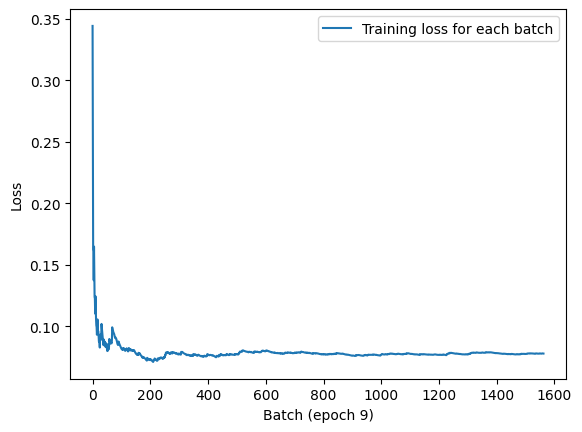

In [ ]:
model = get_mnist_model()
model.compile(optimizer="rmsprop",
loss="sparse_categorical_crossentropy",
metrics=["accuracy"])
model.fit(train_images, train_labels,
epochs=10,
callbacks=[LossHistory()],
validation_data=(val_images, val_labels))

In [ ]:
model=get_mnist_model()
model.compile(optimizer="rmsprop",
              loss="sparse_categorical_crossentropy",
              metrics=['accuracy'])
tensorboard=keras.callbacks.TensorBoard(
    log_dir="/full_path_to_your_log_dir",
)
model.fit(train_images,train_labels,
          epochs=10,
          validation_data=(val_images,val_labels),
          callbacks=[tensorboard])

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 15s 9ms/step - accuracy: 0.8598 - loss: 0.4578 - val_accuracy: 0.9576 - val_loss: 0.1456
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 23s 11ms/step - accuracy: 0.9530 - loss: 0.1663 - val_accuracy: 0.9694 - val_loss: 0.1130
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 23s 14ms/step - accuracy: 0.9627 - loss: 0.1324 - val_accuracy: 0.9729 - val_loss: 0.1019
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.9704 - loss: 0.1083 - val_accuracy: 0.9735 - val_loss: 0.0996
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - accuracy: 0.9726 - loss: 0.1027 - val_accuracy: 0.9769 - val_loss: 0.0903
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 16s 9ms/step - accuracy: 0.9740 - loss: 0.0947 - val_accuracy: 0.9773 - val_loss: 0.0927
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.9757 - loss: 0.0876 - val_accuracy: 0.9771 - val_loss: 0.1007
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - accuracy: 0.9778 - l

In [ ]:
%load_ext tensorboard
%tensorboard --logdir /full_path_to_your_log_dir

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


Reusing TensorBoard on port 6006 (pid 15580), started 0:01:01 ago. (Use '!kill 15580' to kill it.)

<IPython.core.display.Javascript object>

In [ ]:
def train_step(inputs, targets):
  with tf.GradientTape() as tape:
  predictions = model(inputs, training=True)
  loss = loss_fn(targets, predictions)

  gradients = tape.gradients(loss, model.trainable_weights)
  optimizer.apply_gradients(zip(model.trainable_weights, gradients))

IndentationError: expected an indented block after 'with' statement on line 2 (<ipython-input-70-fe8e71c21bd4>, line 3)

In [ ]:
model = get_mnist_model()
loss_fn = keras.losses.SparseCategoricalCrossentropy()
optimizer = keras.optimizers.RMSprop()
metrics = [keras.metrics.SparseCategoricalAccuracy()]
loss_tracking_metric = keras.metrics.Mean()

def train_step(inputs, targets):
  with tf.GradientTape() as tape:
  predictions = model(inputs, training=True)
  loss = loss_fn(targets, predictions)
  gradients = tape.gradient(loss, model.trainable_weights)
  optimizer.apply_gradients(zip(gradients, model.trainable_weights))
  ogs = {}
  for metric in metrics:
    metric.update_state(targets, predictions)
    logs[metric.name] = metric.result()
  loss_tracking_metric.update_state(loss)
  logs["loss"] = loss_tracking_metric.result()
  return logs

IndentationError: expected an indented block after 'with' statement on line 8 (<ipython-input-71-49fdf19e3128>, line 9)

In [ ]:
def reset_metrics():
  for metric in metrics:
      metric.reset_state()
  loss_tracking_metric.reset_state()

In [ ]:
training_dataset = tf.data.Dataset.from_tensor_slices(
(train_images, train_labels))
training_dataset = training_dataset.batch(32)
epochs = 3
for epoch in range(epochs):
  reset_metrics()
  for inputs_batch, targets_batch in training_dataset:
    logs = train_step(inputs_batch, targets_batch)
    print(f"Results at the end of epoch {epoch}")
  for key, value in logs.items():
    print(f"...{key}: {value:.4f}")

NameError: name 'metrics' is not defined

In [ ]:
@tf.function
def test_step(inputs, targets):
  predictions = model(inputs, training=False)
  loss = loss_fn(targets, predictions)
  logs = {}
  for metric in metrics:
  metric.update_state(targets, predictions)
  logs["val_" + metric.name] = metric.result()
  loss_tracking_metric.update_state(loss)
  logs["val_loss"] = loss_tracking_metric.result()
  return logs
  val_dataset = tf.data.Dataset.from_tensor_slices((val_images, val_labels))
  val_dataset = val_dataset.batch(32)
  reset_metrics()

# Chapter 08

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

inputs=keras.Input(shape=(28,28,1))
x=layers.Conv2D(filters=32,kernel_size=3,activation="relu")(inputs)
x=layers.MaxPooling2D(pool_size=2)(x)
x=layers.Conv2D(filters=64,kernel_size=3,activation="relu")(x)
x=layers.MaxPooling2D(pool_size=2)(x)
x=layers.Conv2D(filters=128,kernel_size=3,activation="relu")(x)
x=layers.Flatten()(x)

outputs=layers.Dense(10,activation="softmax")(x)
model=keras.Model(inputs=inputs,outputs=outputs)

In [ ]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        11,530 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,202 (407.04 KB)

 Trainable params: 104,202 (407.04 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.datasets import mnist
(train_images,train_labels),(test_images,test_labels)=mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
train_images = train_images.reshape((60000, 28, 28, 1))
train_images = train_images.astype("float32") / 255
test_images = test_images.reshape((10000, 28, 28, 1))
test_images = test_images.astype("float32") / 255

In [ ]:
model.compile(optimizer="rmsprop",
loss="sparse_categorical_crossentropy",
metrics=["accuracy"])
model.fit(train_images, train_labels, epochs=5, batch_size=64)

Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 53s 52ms/step - accuracy: 0.8845 - loss: 0.3649
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 80s 51ms/step - accuracy: 0.9854 - loss: 0.0462
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 98s 68ms/step - accuracy: 0.9911 - loss: 0.0292
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 84s 71ms/step - accuracy: 0.9932 - loss: 0.0213
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 73s 78ms/step - accuracy: 0.9952 - loss: 0.0161


In [ ]:
test_loss,test_acc=model.evaluate(test_images,test_labels)
print(f"test acc:{test_acc:.3f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9889 - loss: 0.0319
test acc:0.992


In [ ]:
inputs = keras.Input(shape=(28, 28, 1))
x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(inputs)
x=layers.Conv2D(filters=64,kernel_size=3,activation="relu")(x)
x=layers.Conv2D(filters=128,kernel_size=3,activation="relu")(x)
x=layers.Flatten()(x)
outputs=layers.Dense(10,activation="softmax")(x)
model_no_max_pool=keras.Model(inputs=inputs,outputs=outputs)

In [ ]:
model_no_max_pool.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 22, 22, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 61952)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │       619,530 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 712,202 (2.72 MB)

 Trainable params: 712,202 (2.72 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from google.colab import files
files.upload()

!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle competitions download -c dogs-vs-cats
!unzip -qq train.zip


Saving kaggle.json to kaggle (2).json
mkdir: cannot create directory ‘/root/.kaggle’: File exists
dogs-vs-cats.zip: Skipping, found more recently modified local copy (use --force to force download)
unzip:  cannot find or open train.zip, train.zip.zip or train.zip.ZIP.


In [ ]:
# পুনরায় Kaggle API দিয়ে ডাউনলোড করো
!kaggle competitions download -c dogs-vs-cats --force


100% 812M/812M [00:07<00:00, 182MB/s]
100% 812M/812M [00:07<00:00, 108MB/s]


In [ ]:
!unzip -q dogs-vs-cats.zip -d dogs-vs-cats
!unzip -q dogs-vs-cats/train.zip -d dogs-vs-cats/train
!ls dogs-vs-cats/train | head


train


In [ ]:
# import os, shutil, pathlib
# original_dir = pathlib.Path("train")
# new_base_dir = pathlib.Path("cats_vs_dogs_small")

# def make_subset(subset_name, start_index, end_index):
#   for category in ("cat", "dog"):
#       dir = new_base_dir / subset_name / category
#       os.makedirs(dir,exist_ok=True)
#       fnames = [f"{category}.{i}.jpg"
#                 for i in range(start_index, end_index)]
#       for fname in fnames:


#           shutil.copyfile(src=original_dir / fname,
#           dst=dir / fname)
# make_subset("train", start_index=0, end_index=1000)
# make_subset("validation", start_index=1000, end_index=1500)
# make_subset("test", start_index=1500, end_index=2500)

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

In [ ]:
inputs=keras.Input(shape=(180,180,3))
x=layers.Rescaling(1./255)(inputs)
x=layers.Conv2D(filters=32,kernel_size=3,activation="relu")(x)
x=layers.MaxPooling2D(pool_size=2)(x)
x=layers.Conv2D(filters=64,kernel_size=3,activation="relu")(x)
x=layers.MaxPooling2D(pool_size=2)(x)
x=layers.Conv2D(filters=128,kernel_size=3,activation="relu")(x)
x=layers.MaxPooling2D(pool_size=2)(x)
x=layers.Conv2D(filters=256,kernel_size=3,activation="relu")(x)
x=layers.MaxPooling2D(pool_size=2)(x)
x=layers.Conv2D(filters=256,kernel_size=3,activation="relu")(x)

x=layers.Flatten()(x)
outputs=layers.Dense(1,activation="sigmoid")(x)
model=keras.Model(inputs=inputs,outputs=outputs)

In [ ]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 18, 18, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 7, 7, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │        12,545 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 991,041 (3.78 MB)

 Trainable params: 991,041 (3.78 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer="rmsprop",
              loss="binary_crossentropy",
              metrics=["accuracy"])

In [ ]:
from tensorflow.keras.utils import image_dataset_from_directory

In [ ]:
# from tensorflow.keras.utils import image_dataset_from_directory
# train_dataset = image_dataset_from_directory(
# new_base_dir / "train",
# image_size=(180, 180),
# batch_size=32)
# validation_dataset = image_dataset_from_directory(
# new_base_dir / "validation",
# image_size=(180, 180),
# batch_size=32)
# test_dataset = image_dataset_from_directory(
# new_base_dir / "test",
# image_size=(180, 180),
# batch_size=32)

In [ ]:
# for data_batch,labels_batch in train_dataset:
#   print("data batch shape:",data_batch.shape)
#   print("labels batch shape:",labels_batch.shape)
#   break

In [ ]:
conv_base=keras.applications.vgg16.VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(180,180,3)
)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [ ]:
conv_base.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 180, 180, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 180, 180, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 90, 90, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 90, 90, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 90, 90, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 45, 45, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 45, 45, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 45, 45, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 45, 45, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 22, 22, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 22, 22, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 22, 22, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 22, 22, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 11, 11, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 11, 11, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 11, 11, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 11, 11, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 5, 5, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
import numpy as np
def get_features_and_labels(dataset):
  all_features=[]
  all_labels=[]
  for images,labels in dataset:
    preprocessed_images=tf.keras.applications.vgg16.preprocess_input(images)
    features=conv_base.predict(preprocessed_images)
    all_features.append(features)
    all_labels.append(labels)
  return np.concatenate(all_features),np.concatenate(all_labels)

# train_features,train_labels=get_features_and_labels(train_dataset)
# val_features,val_labels=get_features_and_labels(validation_dataset)
# test_features,test_labels=get_features_and_labels(test_dataset)

In [ ]:
inputs=keras.Input(shape=(5,5,512))
x=layers.Flatten()(inputs)
x=layers.Dense(256)(x)
x=layers.Dropout(0.5)(x)
outputs=layers.Dense(1,activation="sigmoid")(x)
model=keras.Model(inputs,outputs)

In [ ]:
model.compile(loss="binary_crossentropy",
optimizer="rmsprop",
metrics=["accuracy"])

callbacks = [
keras.callbacks.ModelCheckpoint(
filepath="feature_extraction.keras",
save_best_only=True,
monitor="val_loss")
]

In [ ]:
# history = model.fit(
# train_features, train_labels,
# epochs=20,
# validation_data=(val_features, val_labels),
# callbacks=callbacks)

In [ ]:
conv_base = keras.applications.vgg16.VGG16(
weights="imagenet",
include_top=False)
conv_base.trainable = False

In [ ]:
conv_base.trainable = True

In [ ]:
print("This is the number of trainable weights "
"before freezing the conv base:", len(conv_base.trainable_weights))


This is the number of trainable weights before freezing the conv base: 26


In [ ]:
conv_base.trainable = False

In [ ]:
print("This is the number of trainable weights "
"before freezing the conv base:", len(conv_base.trainable_weights))

This is the number of trainable weights before freezing the conv base: 0


In [ ]:
data_augmentation=keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.2)
])

In [ ]:
inputs = keras.Input(shape=(180, 180, 3))
x = data_augmentation(inputs)
x = keras.applications.vgg16.preprocess_input(x)
x = conv_base(x)
x = layers.Flatten()(x)
x = layers.Dense(256)(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model = keras.Model(inputs, outputs)
model.compile(loss="binary_crossentropy",
optimizer="rmsprop",
metrics=["accuracy"])

In [ ]:
callbacks = [
keras.callbacks.ModelCheckpoint(
filepath="feature_extraction_with_data_augmentation.keras",
save_best_only=True,
monitor="val_loss")
]

In [ ]:
# history = model.fit(
# train_dataset,
# epochs=50,
# validation_data=validation_dataset,
# callbacks=callbacks)

In [ ]:
conv_base.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, None, None, 64) │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, None, None, 64) │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, None, None, 64) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, None, None,     │        73,856 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, None, None,     │       147,584 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, None, None,     │       295,168 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, None, None,     │       590,080 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, None, None,     │       590,080 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, None, None,     │     1,180,160 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │             

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

# Chapter 09

In [ ]:
!wget http://www.robots.ox.ac.uk/~vgg/data/pets/data/images.tar.gz
!wget http://www.robots.ox.ac.uk/~vgg/data/pets/data/annotations.tar.gz
!tar -xf images.tar.gz
!tar -xf annotations.tar.gz

--2025-05-01 03:44:54--  http://www.robots.ox.ac.uk/~vgg/data/pets/data/images.tar.gz
Resolving www.robots.ox.ac.uk (www.robots.ox.ac.uk)... 129.67.94.2
Connecting to www.robots.ox.ac.uk (www.robots.ox.ac.uk)|129.67.94.2|:80... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://www.robots.ox.ac.uk/~vgg/data/pets/data/images.tar.gz [following]
--2025-05-01 03:44:54--  https://www.robots.ox.ac.uk/~vgg/data/pets/data/images.tar.gz
Connecting to www.robots.ox.ac.uk (www.robots.ox.ac.uk)|129.67.94.2|:443... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://thor.robots.ox.ac.uk/pets/images.tar.gz [following]
--2025-05-01 03:44:55--  https://thor.robots.ox.ac.uk/pets/images.tar.gz
Resolving thor.robots.ox.ac.uk (thor.robots.ox.ac.uk)... 129.67.95.98
Connecting to thor.robots.ox.ac.uk (thor.robots.ox.ac.uk)|129.67.95.98|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 791918971 (755M) [app

In [ ]:
import os
input_dir = "images/"
target_dir = "annotations/trimaps/"

input_img_paths = sorted(
  [os.path.join(input_dir, fname)
  for fname in os.listdir(input_dir)
  if fname.endswith(".jpg")])


target_paths = sorted(
  [os.path.join(target_dir, fname)
  for fname in os.listdir(target_dir)
  if fname.endswith(".png") and not fname.startswith(".")])

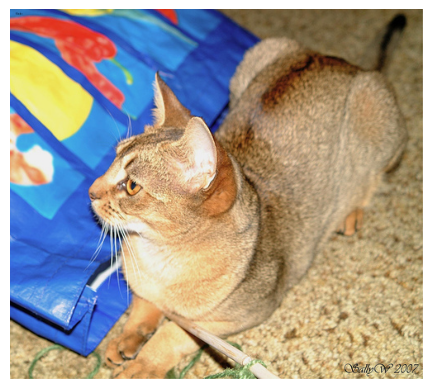

In [ ]:
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img

plt.axis("off")
plt.imshow(load_img(input_img_paths[9]))

In [ ]:
from tensorflow.keras.preprocessing.image import img_to_array,load_img


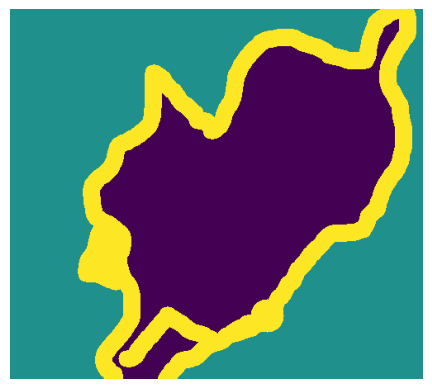

In [ ]:
def display_target(target_array):
  normalized_array=(target_array.astype("uint8")-1)*127
  plt.axis("off")
  plt.imshow(normalized_array[:,:,0])
img=img_to_array(load_img(target_paths[9],color_mode="grayscale"))
display_target(img)

In [ ]:
import numpy as np
import random

In [ ]:
img_size=(200,200)
num_imgs=len(input_img_paths)

random.Random(1337).shuffle(input_img_paths)
random.Random(1337).shuffle(target_paths)

def path_to_input_image(path):
  return img_to_array(load_img(path,target_size=img_size))

def path_to_target(path):
  img=img_to_array(
      load_img(path,target_size=img_size,color_mode="grayscale")
  )
  img=img.astype("uint8")-1
  return img

input_imgs=np.zeros((num_imgs,)+img_size+(3,),dtype="float32")
targets=np.zeros((num_imgs,)+img_size+(1,),dtype="uint8")
for i in range(num_imgs):
  input_imgs[i]=path_to_input_image(input_img_paths[i])
  targets[i]=path_to_target(target_paths[i])

num_val_samples=1000
train_input_imgs=input_imgs[:-num_val_samples]
train_targets=targets[:-num_val_samples]
val_input_imgs=input_imgs[-num_val_samples]
val_targets=targets[-num_val_samples]

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

def get_model(img_size,num_classes):
  inputs=keras.Input(shape=img_size+(3,))
  x=layers.Rescaling(1./255)(inputs)

  x=layers.Conv2D(64,3,strides=2,activation="relu",padding="same")(x)
  x=layers.Conv2D(64,3,activation="relu",padding="same")(x)
  x=layers.Conv2D(128,3,strides=2,activation="relu",padding="same")(x)
  x=layers.Conv2D(128,3,activation="relu",padding="same")(x)
  x=layers.Conv2D(256,3,strides=2,activation="relu",padding="same")(x)


  x=layers.Conv2DTranspose(256,3,activation="relu",padding="same")(x)
  x=layers.Conv2DTranspose(256,3,activation="relu",padding="same",strides=2)(x)

  x=layers.Conv2DTranspose(128,3,activation="relu",padding="same")(x)
  x=layers.Conv2DTranspose(128,3,activation="relu",padding="same",strides=2)(x)


  x=layers.Conv2DTranspose(64,3,activation="relu",padding="same")(x)
  x=layers.Conv2DTranspose(64,3,activation="relu",padding="same",strides=2)(x)

  outputs=layers.Conv2D(num_classes,3,activation="softmax",padding="same")(x)

  model=keras.Model(inputs,outputs)
  return model

model=get_model(img_size=img_size,num_classes=3)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 200, 200, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 200, 200, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 100, 100, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 100, 100, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 50, 50, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 50, 50, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 25, 25, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 25, 25, 256)    │       590,080 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 50, 50, 256)    │       590,080 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 50, 50, 128)    │       295,040 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 100, 100, 128)  │       147,584 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_4              │ (None, 100, 100, 64)   │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_5              │ (None, 200, 200, 64)   │        36,928 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 200, 200, 3)    │         1,731 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,290,563 (8.74 MB)

 Trainable params: 2,290,563 (8.74 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer="rmsprop",loss="sparse_categorical_crossentropy")

callbacks=[
    keras.callbacks.ModelCheckpoint("oxford_segmentation.keras",
                                    save_best_only=True)
]
history=model.fit(train_input_imgs,train_targets,
                  epochs=50,
                  callbacks=callbacks,
                  validation_data=(val_input_imgs,val_targets))

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 22s/step - loss: 0.9528 

ValueError: Input 0 of layer "functional" is incompatible with the layer: expected shape=(None, 200, 200, 3), found shape=(None, 200, 3)

In [ ]:
val_loss=history.history["val_loss"]
plt.figure()
plt.plot(epochs,loss,"bo",label="training loss")
plt.plot(epochs,val_loss,"b",label="validation loss")

plt.title("Training and validation loss")
plt.legend()
plt.show()

In [ ]:
from tensorflw.keras.utils import array_to_img
model=keras.models.load_model("oxford_segmentation.keras")
i=4
test_image=val_input_imgs[i]
plt.axis("off")
plt.imshow(array_to_img(test_image))
msk=model.predict(np.expand_dims(text_image,0))[0]

def display_mask(pred):
  mask=np.argmax(pred,axis=-1)
  mask*=127
  plt.axis("off")
  plt.imshow(mask)

display_mask(msk)


ModuleNotFoundError: No module named 'tensorflw'

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

inputs=keras.Input(shape=(32,32,3))
x=layers.Conv2D(32,3,activation="relu")(inputs)
residual=x
x=layers.Conv2D(64,3,activation="relu",padding="same")(x)
residual=layers.Conv2D(64,1)(residual)
x=layers.add([x,residual])



In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

inputs=keras.Input(shape=(32,32,3))
x=layers.Conv2D(32,3,activation="relu")(inputs)
residual=x
x=layers.Conv2D(64,3,activation="relu",padding="same")(x)
x=layers.MaxPooling2D(2,padding="same")(x)
residual=layers.Conv2D(64,1,strides=2)(residual)
x=layers.add([x,residual])

In [ ]:
inputs=keras.Input(shape=(32,32,2))
x=layers.Rescaling(1./255)(inputs)

def residual_block(x,filters,pooling=False):
  residual=x
  x=layers.Conv2D(filters,3,activation="relu",padding="same")(x)
  x=layers.Conv2D(filters,3,activation="relu",padding="same")(x)
  if pooling:
    x=layers.MaxPooling2D(2,padding="same")(x)
    residual=layers.Conv2D(filters,1,strides=2)(residual)
  elif filters != residual.shape[-1]:
    residual=layers.Conv2D(filters,1)(residual)
  x=layers.add([x,residual])
  return x

x=residual_block(x,filters=32,pooling=True)
x=residual_block(x,filters=64,pooling=True)
x=residual_block(x,filters=128,pooling=False)

x=layers.GlobalAveragePooling2D()(x)
outputs=layers.Dense(1,activation="sigmoid")(x)
model=keras.Model(inputs=inputs,outputs=outputs)

In [ ]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 32, 32, 2) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 32, 32, 2) │          0 │ input_layer_2[0]… │
│ (Rescaling)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 32, 32,    │        608 │ rescaling_1[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 32, 32,    │      9,248 │ conv2d_9[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 16, 16,    │          0 │ conv2d_10[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 16, 16,    │         96 │ rescaling_1[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 16, 16,    │          0 │ max_pooling2d[0]… │
│                     │ 32)               │            │ conv2d_11[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 16, 16,    │     18,496 │ add_1[0][0]       │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, 16, 16,    │     36,928 │ conv2d_12[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 8, 8, 64)  │          0 │ conv2d_13[0][0]   │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_14 (Conv2D)  │ (None, 8, 8, 64)  │      2,112 │ add_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 8, 8, 64)  │          0 │ max_pooling2d_1[… │
│                     │                   │            │ conv2d_14[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_15 (Conv2D)  │ (None, 8, 8, 128) │     73,856 │ add_2[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_16 (Conv2D)  │ (None, 8, 8, 128) │    147,584 │ conv2d_15[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_17 (Conv2D)  │ (None, 8, 8, 128) │      8,320 │ add_2[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 8, 8, 128) │          0 │ conv2d_16[0][0],  │
│                     │                   │            │ conv2d_17[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ add_3[0][0]       │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 1)         │        129 │ global_average_p… │
└─────────────────────┴───────────────────┴────────────┴─────────────────

 Total params: 297,377 (1.13 MB)

 Trainable params: 297,377 (1.13 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
data_augmentation=keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.2)
])

In [ ]:
inputs=keras.Input(shape=(180,180,3))

x=data_augmentation(inputs)

x=layers.Rescaling(1./255)(x)
x=layers.Conv2D(filters=64,kernel_size=3,activation="relu")(x)
for size in [32,64,128,256,512]:
  residual=x

  x=layers.BatchNormalization()(x)
  x=layers.Activation("relu")(x)
  x=layers.SeparableConv2D(size,3,padding="same",use_bias=False)(x)

  x=layers.BatchNormalization()(x)
  x=layers.Activation("relu")(x)
  x=layers.SeparableConv2D(size,3,padding="same",use_bias=False)(x)

  x=layers.MaxPooling2D(3,strides=2,padding="same")(x)

  residual=layers.Conv2D(
      size,1,strides=2,padding="same",use_bias=False
  )(residual)
  x=layers.add([x,residual])

x=layers.GlobalAveragePooling2D()(x)
x=layers.Dropout(0.5)(x)
outputs=layers.Dense(1,activation="sigmoid")(x)
model=keras.Model(inputs=inputs,outputs=outputs)


In [ ]:
from tensorflow import  keras
model=keras.models.load_model("convnet_from_scratch_with_augmentation.keras")


ValueError: File not found: filepath=convnet_from_scratch_with_augmentation.keras. Please ensure the file is an accessible `.keras` zip file.

In [ ]:
model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 180, 180,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 180, 180,  │          0 │ input_layer_3[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_2         │ (None, 180, 180,  │          0 │ sequential[0][0]  │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_18 (Conv2D)  │ (None, 178, 178,  │      1,792 │ rescaling_2[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 178, 178,  │        256 │ conv2d_18[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 178, 178,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d    │ (None, 178, 178,  │      2,624 │ activation[0][0]  │
│ (SeparableConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 178, 178,  │        128 │ separable_conv2d… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 178, 178,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_1  │ (None, 178, 178,  │      1,312 │ activation_1[0][… │
│ (SeparableConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 89, 89,    │          0 │ separable_conv2d… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 89, 89,    │      2,048 │ conv2d_18[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 89, 89,    │          0 │ max_pooling2d_2[… │
│                     │ 32)               │            │ conv2d_19[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 89, 89,    │        128 │ add_4[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 89, 89,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_2  │ (None, 89, 89,    │      2,336 │ activation_2[0][… │
│ (SeparableConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 89, 89,    │        256 │ separable_conv2d

 Total params: 723,713 (2.76 MB)

 Trainable params: 720,641 (2.75 MB)

 Non-trainable params: 3,072 (12.00 KB)

In [ ]:
from tensorflow import keras

from tensorflow.keras.preprocessing.image import img_to_array

import numpy as np
img_path=keras.utils.get_file(
    fname="cat.jpg",
    origin="https://img-datasets.s3.amazonaws.com/cat.jpg"
)

def get_img_array(img_path,target_size):
  img=keras.utils.load_img(
      img_path,target_size=target_size
  )
  array=keras.utils.img_to_array(img)
  array=np.expand_dims(array,axis=0)
  return array

img_tensor=get_img_array(img_path,target_size=(180,180))

80329/80329 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step


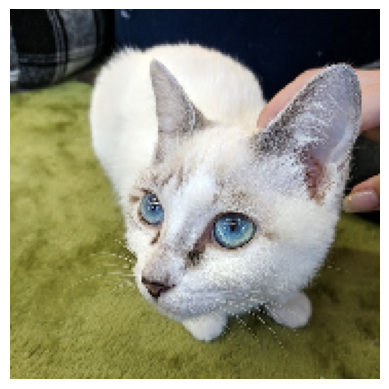

In [ ]:
import matplotlib.pyplot as plt
plt.axis("off")
plt.imshow(img_tensor[0].astype("uint8"))
plt.show()

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers,models
layer_outputs = []
layer_names = []
for layer in model.layers:
  if isinstance(layer, (layers.Conv2D, layers.MaxPooling2D)):
    layer_outputs.append(layer.output)
    layer_names.append(layer.name)
activation_model = keras.Model(inputs=model.input, outputs=layer_outputs)


ImportError: cannot import name 'model' from 'tensorflow.keras' (/usr/local/lib/python3.11/dist-packages/keras/_tf_keras/keras/__init__.py)

In [ ]:
activations = activation_model.predict(img_tensor)

NameError: name 'activation_model' is not defined

In [ ]:
images_per_row = 16
for layer_name, layer_activation in zip(layer_names, activations):
  n_features = layer_activation.shape[-1]
  size = layer_activation.shape[1]
  n_cols = n_features // images_per_row
  display_grid = np.zeros(((size + 1) * n_cols - 1,
  images_per_row * (size + 1) - 1))
  for col in range(n_cols):
    for row in range(images_per_row):
      channel_index = col * images_per_row + row
      channel_image = layer_activation[0, :, :, channel_index].copy()

  if channel_image.sum() != 0:
    channel_image -= channel_image.mean()
    channel_image /= channel_image.std()
    channel_image *= 64
    channel_image += 128
  channel_image = np.clip(channel_image, 0, 255).astype("uint8")
  display_grid[
  col * (size + 1): (col + 1) * size + col,
  row * (size + 1) : (row + 1) * size + row] = channel_image
scale = 1. / size
plt.figure(figsize=(scale * display_grid.shape[1],
scale * display_grid.shape[0]))
plt.title(layer_name)
plt.grid(False)
plt.axis("off")
plt.imshow(display_grid, aspect="auto", cmap="viridis")

NameError: name 'activations' is not defined

# Chapeter 10

In [ ]:
!wget https://s3.amazonaws.com/keras-datasets/jena_climate_2009_2016.csv.zip
!unzip jena_climate_2009_2016.csv.zip

--2025-05-02 04:40:42--  https://s3.amazonaws.com/keras-datasets/jena_climate_2009_2016.csv.zip
Resolving s3.amazonaws.com (s3.amazonaws.com)... 3.5.22.28, 52.216.239.125, 52.217.228.216, ...
Connecting to s3.amazonaws.com (s3.amazonaws.com)|3.5.22.28|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 13565642 (13M) [application/zip]
Saving to: ‘jena_climate_2009_2016.csv.zip’

jena_climate_2009_2 100%[===================>]  12.94M  25.2MB/s    in 0.5s    

2025-05-02 04:40:43 (25.2 MB/s) - ‘jena_climate_2009_2016.csv.zip’ saved [13565642/13565642]

Archive:  jena_climate_2009_2016.csv.zip
  inflating: jena_climate_2009_2016.csv  
  inflating: __MACOSX/._jena_climate_2009_2016.csv  


In [ ]:
import os
fname = os.path.join("jena_climate_2009_2016.csv")

with open(fname) as f:
    data = f.read()

lines=data.split("\n")
header=lines[0].split(",")
lines=lines[1:]
print(header)
print(len(lines))

['"Date Time"', '"p (mbar)"', '"T (degC)"', '"Tpot (K)"', '"Tdew (degC)"', '"rh (%)"', '"VPmax (mbar)"', '"VPact (mbar)"', '"VPdef (mbar)"', '"sh (g/kg)"', '"H2OC (mmol/mol)"', '"rho (g/m**3)"', '"wv (m/s)"', '"max. wv (m/s)"', '"wd (deg)"']
420451


In [ ]:
import numpy as np
temperature =np.zeros((len(lines),))
raw_data=np.zeros((len(lines),len(header)-1))
for i,line in enumerate(lines):
  values=[float (x) for x in line.split(",")[1:]]
  temperature[i]=values[1]
  raw_data[i,:]=values[:]



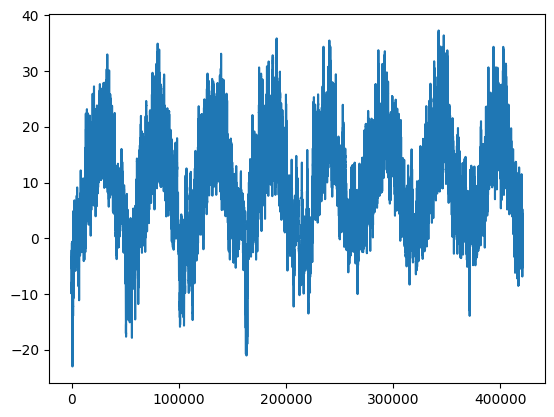

In [ ]:
from matplotlib import  pyplot as plt
plt.plot(range(len(temperature)),temperature)

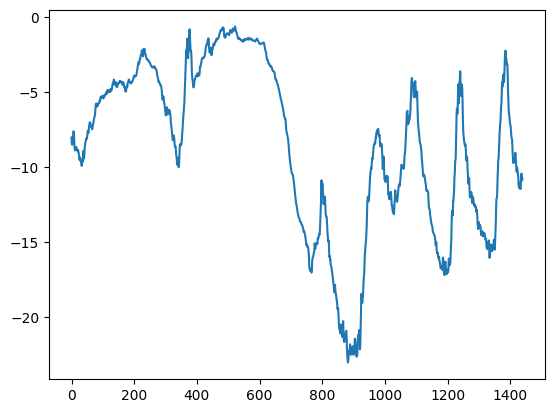

In [ ]:
plt.plot(range(1440),temperature[:1440])


In [ ]:
num_train_samples=int(0.5*len(raw_data))
num_val_samples=int(0.25*len(raw_data))
num_test_samples=len(raw_data)-num_train_samples-num_val_samples


In [ ]:
print("Number of training samples:", num_train_samples)
print("Number of validation samples:", num_val_samples)
print("Number of testing samples:", num_test_samples)

Number of training samples: 210225
Number of validation samples: 105112
Number of testing samples: 105114


# chapter 12
